       DEEP LEARNING VISUAL LAB

Dataset samples : 569
Input features  : 30
Missing values  : 0

Class distribution:
target
benign       357
malignant    212
Name: count, dtype: int64

Training neural network...
Training completed successfully!

MODEL PERFORMANCE
---------------------------------------------
Accuracy       : 0.9649 (96.49%)
Precision      : 0.9722 (97.22%)
Recall         : 0.9722 (97.22%)
F1 Score       : 0.9722 (97.22%)
ROC-AUC        : 0.9950 (99.50%)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        42
      benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114

Calculating permutation feature importance...


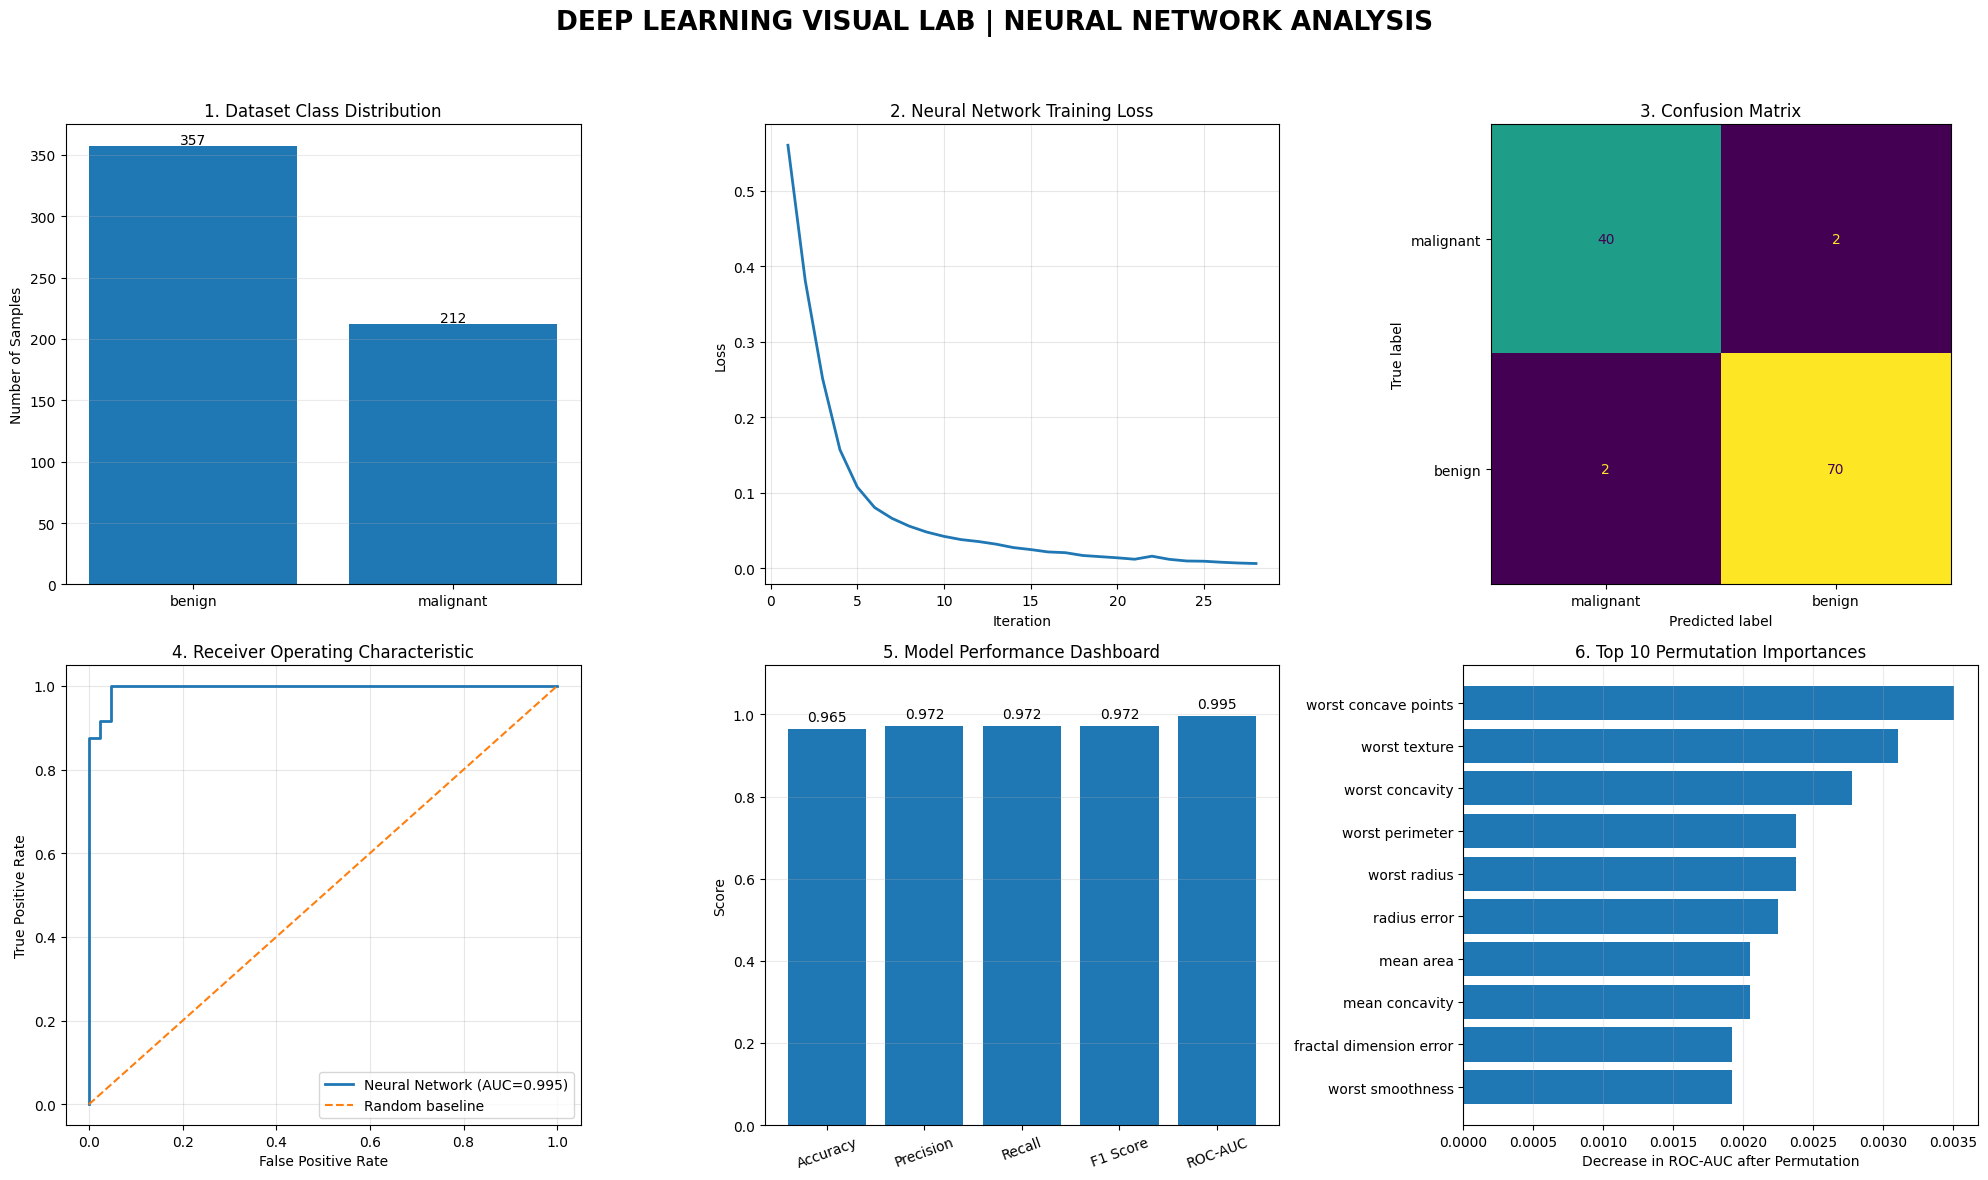


FINAL PROJECT REPORT
Neural network architecture : (64, 32, 16)
Activation function         : relu
Optimization algorithm      : adam
Training iterations         : 28
Training samples            : 455
Testing samples             : 114

TOP 10 FEATURES
                Feature  Importance
   worst concave points    0.003505
          worst texture    0.003108
        worst concavity    0.002778
        worst perimeter    0.002381
           worst radius    0.002381
           radius error    0.002249
         mean concavity    0.002050
              mean area    0.002050
fractal dimension error    0.001918
       worst smoothness    0.001918

CONCEPTS DEMONSTRATED

1. Artificial neural networks and hidden layers
2. ReLU activation function
3. Forward propagation and prediction
4. Backpropagation through the training algorithm
5. Adam optimization
6. Feature standardization
7. Training loss and convergence
8. Confusion matrix and classification metrics
9. ROC curve and AUC
10. Permutatio

In [2]:



import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay,
    classification_report
)
from sklearn.inspection import permutation_importance

# 1. LOAD DATA
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

print("=" * 70)
print("       DEEP LEARNING VISUAL LAB")
print("=" * 70)
print(f"\nDataset samples : {X.shape[0]}")
print(f"Input features  : {X.shape[1]}")
print(f"Missing values  : {X.isnull().sum().sum()}")
print("\nClass distribution:")
print(y.map(dict(enumerate(data.target_names))).value_counts())

# 2. TRAIN-TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# 3. STANDARDIZE FEATURES
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. BUILD AND TRAIN NEURAL NETWORK
model = MLPClassifier(
    hidden_layer_sizes=(64, 32, 16),
    activation="relu",
    solver="adam",
    alpha=0.001,
    batch_size=32,
    learning_rate_init=0.001,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    random_state=42
)

print("\nTraining neural network...")
model.fit(X_train_scaled, y_train)
print("Training completed successfully!")

# 5. PREDICTIONS
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

print("\nMODEL PERFORMANCE")
print("-" * 45)
for name, value in metrics.items():
    print(f"{name:<15}: {value:.4f} ({value:.2%})")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test, y_pred,
    target_names=data.target_names,
    zero_division=0
))

# 6. FEATURE IMPORTANCE
print("Calculating permutation feature importance...")
importance = permutation_importance(
    model,
    X_test_scaled,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

# 7. SIX ADVANCED VISUALIZATIONS
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle(
    "DEEP LEARNING VISUAL LAB | NEURAL NETWORK ANALYSIS",
    fontsize=19,
    fontweight="bold"
)

# Visualization 1: Dataset distribution
counts = y.map(dict(enumerate(data.target_names))).value_counts()
axes[0, 0].bar(counts.index, counts.values)
axes[0, 0].set_title("1. Dataset Class Distribution")
axes[0, 0].set_ylabel("Number of Samples")
axes[0, 0].grid(axis="y", alpha=0.25)

for i, value in enumerate(counts.values):
    axes[0, 0].text(i, value + 2, str(value), ha="center")

# Visualization 2: Training loss
axes[0, 1].plot(
    range(1, len(model.loss_curve_) + 1),
    model.loss_curve_,
    linewidth=2
)
axes[0, 1].set_title("2. Neural Network Training Loss")
axes[0, 1].set_xlabel("Iteration")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].grid(True, alpha=0.3)

# Visualization 3: Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=data.target_names,
    ax=axes[0, 2],
    colorbar=False
)
axes[0, 2].set_title("3. Confusion Matrix")

# Visualization 4: ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1, 0].plot(
    fpr, tpr, linewidth=2,
    label=f"Neural Network (AUC={metrics['ROC-AUC']:.3f})"
)
axes[1, 0].plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
axes[1, 0].set_title("4. Receiver Operating Characteristic")
axes[1, 0].set_xlabel("False Positive Rate")
axes[1, 0].set_ylabel("True Positive Rate")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Visualization 5: Evaluation metrics
names = list(metrics.keys())
values = list(metrics.values())
axes[1, 1].bar(names, values)
axes[1, 1].set_title("5. Model Performance Dashboard")
axes[1, 1].set_ylabel("Score")
axes[1, 1].set_ylim(0, 1.12)
axes[1, 1].tick_params(axis="x", rotation=20)
axes[1, 1].grid(axis="y", alpha=0.25)

for i, value in enumerate(values):
    axes[1, 1].text(i, value + 0.02, f"{value:.3f}", ha="center")

# Visualization 6: Top 10 features
top10 = importance_df.head(10).sort_values("Importance")
axes[1, 2].barh(top10["Feature"], top10["Importance"])
axes[1, 2].set_title("6. Top 10 Permutation Importances")
axes[1, 2].set_xlabel("Decrease in ROC-AUC after Permutation")
axes[1, 2].grid(axis="x", alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# 8. FINAL REPORT
print("\n" + "=" * 70)
print("FINAL PROJECT REPORT")
print("=" * 70)
print(f"Neural network architecture : {model.hidden_layer_sizes}")
print(f"Activation function         : {model.activation}")
print(f"Optimization algorithm      : {model.solver}")
print(f"Training iterations         : {model.n_iter_}")
print(f"Training samples            : {len(X_train)}")
print(f"Testing samples             : {len(X_test)}")

print("\nTOP 10 FEATURES")
print(importance_df.head(10).to_string(index=False))

print("\nCONCEPTS DEMONSTRATED")
print("""
1. Artificial neural networks and hidden layers
2. ReLU activation function
3. Forward propagation and prediction
4. Backpropagation through the training algorithm
5. Adam optimization
6. Feature standardization
7. Training loss and convergence
8. Confusion matrix and classification metrics
9. ROC curve and AUC
10. Permutation-based feature importance
""")

print("Educational demonstration completed successfully.")
print(
    "DISCLAIMER: This model is for educational purposes only. "
    "It must not be used to diagnose cancer or guide clinical treatment."
)